# Forecasting Baselines — Italian Electricity Prices (2024)

This notebook builds **day-ahead-compatible historical baselines** from the local GME 2024 Excel dataset. Forecasts are assumed to be issued at **12:00 on day D−1** for every market hour of target day D. Therefore, prices from D−1 after noon cannot be used.

The earlier *previous-day, same-hour* experiment in the source notebook is intentionally excluded from the operational comparison: it is not generally available at issuance time. The source notebook is preserved separately as an experiment archive.

**Data source:** [GME historical MGP data](https://gme.mercatoelettrico.org/Home/Esiti/Elettricita/MGP/Statistiche/DatiStorici). Download the source file yourself and respect its usage terms. The dataset is not distributed in this repository.

## 1. Load and validate source data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Run Jupyter from the notebooks/ directory, as in notebook 01.
source = Path("../data/Anno 2024_12.xlsx")
if not source.exists():
    raise FileNotFoundError(f"Missing source Excel file: {source.resolve()}")
raw = pd.read_excel(source, sheet_name="Prezzi-Prices")

prices = raw.iloc[:, :3].copy()
prices.columns = ["date", "hour", "price"]
prices["date"] = pd.to_datetime(prices["date"].astype(str), format="%Y%m%d")
prices = prices.sort_values(["date", "hour"]).reset_index(drop=True)

assert len(prices) == 8784, "Unexpected number of rows for GME 2024"
assert not prices[["date", "hour", "price"]].isna().any().any()
assert not prices.duplicated(["date", "hour"]).any()
print("Observations:", len(prices))
print("Calendar days:", prices.date.nunique())
print("Hours per day:", prices.groupby("date").size().value_counts().sort_index().to_dict())

Observations: 8784
Calendar days: 366
Hours per day: {23: 1, 24: 364, 25: 1}


## 2. Calendar-aligned historical prices

A baseline using the same market hour **two calendar days earlier** is available by the issuance deadline. We also evaluate the same hour **seven days earlier**. Joins use `(date, hour)`, not row offsets, to respect the 23- and 25-hour daylight-saving days.

For a fair later comparison with the final Random Forest, we require the complete historical window D−2 through D−8. This matches the final model's evaluation sample.

In [2]:
baseline_data = prices.copy()
for lag in range(2, 9):
    past = prices[["date", "hour", "price"]].copy()
    past["date"] = past["date"] + pd.Timedelta(days=lag)
    past = past.rename(columns={"price": f"historical_price_{lag}"})
    baseline_data = baseline_data.merge(past, on=["date", "hour"], how="left", validate="one_to_one")

historical_cols = [f"historical_price_{lag}" for lag in range(2, 9)]
baseline_data = baseline_data.dropna(subset=historical_cols).copy()
baseline_data["prediction_2days"] = baseline_data["historical_price_2"]
baseline_data["prediction_7days"] = baseline_data["historical_price_7"]
print("Complete-window observations:", len(baseline_data))
print(baseline_data[["date", "hour", "price", "prediction_2days", "prediction_7days"]].head())

Complete-window observations: 8584
          date  hour     price  prediction_2days  prediction_7days
192 2024-01-09     1  87.53150             96.85            105.49
193 2024-01-09     2  86.18151             96.58             90.09
194 2024-01-09     3  85.00494             93.80             84.27
195 2024-01-09     4  84.08453             93.80             84.27
196 2024-01-09     5  84.97701             85.93             84.27


## 3. Chronological evaluation periods

- **Train:** January–June 2024 (historical feature availability reduces the early-January sample)
- **Validation:** July–September 2024
- **Final test:** October–December 2024, held out for the final model comparison

Baselines have no parameters to fit. The final test results are reported here only as a fixed reference, **not** for selecting a machine-learning model or tuning hyperparameters.

In [3]:
train = baseline_data[baseline_data["date"] < "2024-07-01"].copy()
validation = baseline_data[(baseline_data["date"] >= "2024-07-01") & (baseline_data["date"] < "2024-10-01")].copy()
test = baseline_data[baseline_data["date"] >= "2024-10-01"].copy()
print("Train:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))
assert len(train) == 4168 and len(validation) == 2208 and len(test) == 2208, "Split differs from the final-model sample"

Train: 4168
Validation: 2208
Test: 2208


## 4. Compare two valid historical baselines

In [4]:
def evaluate_baselines(frame):
    rows = []
    for label, column in [("Two-day same-hour", "prediction_2days"),
                          ("Previous-week same-hour", "prediction_7days")]:
        rows.append({
            "Baseline": label,
            "Observations": len(frame),
            "MAE (EUR/MWh)": mean_absolute_error(frame["price"], frame[column]),
            "RMSE (EUR/MWh)": np.sqrt(mean_squared_error(frame["price"], frame[column])),
        })
    return pd.DataFrame(rows)

print("VALIDATION — July to September 2024")
display(evaluate_baselines(validation).round(3))
print("FINAL TEST — October to December 2024 (reference only)")
display(evaluate_baselines(test).round(3))

VALIDATION — July to September 2024


,Baseline,Observations,MAE (EUR/MWh),RMSE (EUR/MWh)
0,Two-day same-hour,2208,12.678,19.056
1,Previous-week same-hour,2208,13.058,19.934


FINAL TEST — October to December 2024 (reference only)


,Baseline,Observations,MAE (EUR/MWh),RMSE (EUR/MWh)
0,Two-day same-hour,2208,16.657,23.591
1,Previous-week same-hour,2208,16.206,23.903


## 5. Hourly error profile on the final test

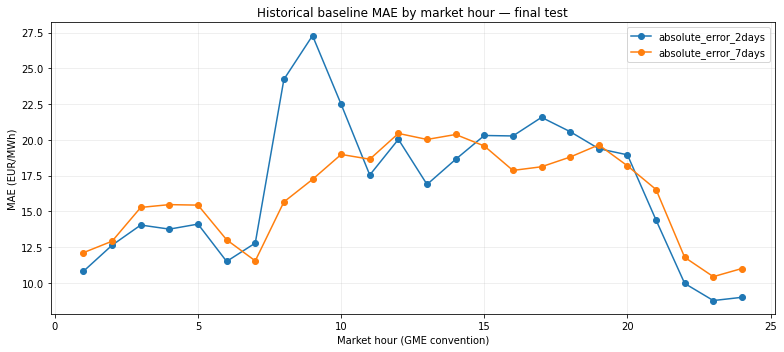

In [5]:
hourly = test.copy()
hourly["absolute_error_2days"] = (hourly["price"] - hourly["prediction_2days"]).abs()
hourly["absolute_error_7days"] = (hourly["price"] - hourly["prediction_7days"]).abs()
by_hour = hourly.groupby("hour")[["absolute_error_2days", "absolute_error_7days"]].mean()
ax = by_hour.plot(figsize=(11, 5), marker="o", title="Historical baseline MAE by market hour — final test")
ax.set_xlabel("Market hour (GME convention)")
ax.set_ylabel("MAE (EUR/MWh)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Interpretation and next steps

- The two-day same-hour baseline is the **operational reference** used in the project's final Random Forest evaluation.
- The weekly baseline is a second valid historical comparator.
- Errors may vary by hour and across unusual price regimes. These descriptive results do not establish future performance.
- The next notebook (`03_model_development.ipynb`) will compare candidate models using **chronological validation**, while keeping the final test out of model selection.
- The eventual external-data milestone will only use forecasts or observations known **by 12:00 on D−1**.